# 04. 머신러닝 — 분류와 회귀, 그리고 평가

> **배우는 것**: 4줄 템플릿(import → 생성 → fit → predict) · 분류 6종 (LogisticRegression, KNN, DecisionTree, RandomForest, XGBoost, LightGBM) · 회귀 3종 · 평가지표 · 특성 중요도 · 임계값 · SMOTE
> ⏱ 예상 소요시간: 70분  |  📑 같이 볼 슬라이드: `slides/04_머신러닝.html`

### 먼저 문제 유형부터!
| 정답(y)이… | 유형 | 모델 이름 끝 | 평가 지표 |
|---|---|---|---|
| 0/1, 등급처럼 **정해진 칸** | **분류** | `...Classifier` | accuracy, precision, recall, f1 |
| 가격, 시간처럼 **연속된 숫자** | **회귀** | `...Regressor` | MAE, MSE, RMSE, R² |

> 공식 샘플은 "도착 시간 예측" → **회귀** (DecisionTreeRegressor + MAE)

### 모든 sklearn 모델은 똑같은 4줄!
```python
from sklearn.ensemble import RandomForestClassifier      # ① 불러오기
model = RandomForestClassifier(n_estimators=100, random_state=42)   # ② 만들기 (하이퍼파라미터)
model.fit(X_train, y_train)                              # ③ 학습 (문제지+답안으로 공부)
pred = model.predict(X_test)                             # ④ 예측 (문제지만 주고 풀기)
```

In [1]:
# ▶ 맨 처음 한 번 실행하세요 (정답 노트북: 한 단계 위 폴더 기준)
import warnings
warnings.filterwarnings('ignore')

import sys
sys.path.insert(0, '..')       # 정답 폴더에서 aice_check 찾기
DATA_DIR = '../../data/'
import aice_check as check

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split

# --- 03 에서 배운 전처리를 한 번에 (그냥 실행) ---
df = pd.read_csv(DATA_DIR + 'telco_churn.csv')
df = df.drop(['customerID', 'DeviceProtection'], axis=1)            # 불필요 / 결측 많은 컬럼
df = df[df['MonthlyCharges'] < 200].dropna()                        # 이상치, 결측 행
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
df['Churn'] = LabelEncoder().fit_transform(df['Churn'])             # No=0, Yes=1
df_preset = pd.get_dummies(df, columns=df.select_dtypes('object').columns, dtype=int)

X = df_preset.drop('Churn', axis=1)
y = df_preset['Churn']
feature_names = X.columns                                           # 스케일링하면 이름이 사라지니 저장
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_train.shape, X_test.shape, y_train.mean().round(3)

((2381, 33), (596, 33), 0.255)

## 1. 분류 — 로지스틱 회귀로 4줄 템플릿 익히기
이름은 '회귀'지만 **분류** 모델이에요 (확률을 계산해서 0.5 기준으로 나눠요).

### ✏️ 문제 1. import
`sklearn.linear_model` 에서 `LogisticRegression` 을 불러오세요.

In [3]:
from sklearn.linear_model import LogisticRegression

<details><summary>💡 힌트 (막히면 클릭)</summary>

모델 위치: linear_model(선형), tree(트리), ensemble(랜덤포레스트 등), neighbors(KNN)

</details>

In [4]:
check.p04_q1()

✅ [P04 문제 1] import — 정답!


### ✏️ 문제 2. 모델 생성 + 학습
**`max_iter=1000`** 으로 모델을 만들어 **`lr`** 에 저장하고 학습시키세요.

In [5]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


<details><summary>💡 힌트 (막히면 클릭)</summary>

max_iter 는 '최대 몇 번 반복해서 답을 찾을지'. 작으면 경고가 날 수 있어요.

</details>

In [6]:
check.p04_q2()

✅ [P04 문제 2] LogisticRegression 학습 — 정답!


### ✏️ 문제 3. 예측
`X_test` 로 예측해서 **`lr_pred`** 에 저장하세요.

In [7]:
lr_pred = lr.predict(X_test)
lr_pred[:10]

array([0, 1, 0, 0, 0, 0, 1, 1, 0, 0])

<details><summary>💡 힌트 (막히면 클릭)</summary>

`model.predict(X_test)`

</details>

In [8]:
check.p04_q3()

✅ [P04 문제 3] 예측 predict — 정답!


## 2. 분류 평가 지표 — 정확도만 보면 속아요!
이탈 고객이 25% 뿐이라면, **무조건 "안 떠남" 이라고 찍어도 정확도 75%** 예요. 그래서 다른 지표도 봐요.

|  | 예측: 안 떠남(0) | 예측: 떠남(1) |
|---|---|---|
| **실제 0** | TN (맞음) | FP (헛경보) |
| **실제 1** | FN (놓침!) | TP (잡음) |

- **정확도 accuracy** = 전체 중 맞힌 비율
- **정밀도 precision** = "떠난다"고 한 것 중 진짜 떠난 비율 = TP / (TP+FP)
- **재현율 recall** = 진짜 떠난 사람 중 잡아낸 비율 = TP / (TP+FN) ← **이탈·사기·질병 탐지에서 중요**
- **F1** = 정밀도와 재현율의 조화평균 (둘 다 챙길 때)

> ⚠️ 함수 인자 순서는 항상 **(정답, 예측)** : `accuracy_score(y_test, pred)`

### ✏️ 문제 4. 지표 4종
정확도·정밀도·재현율·F1 을 각각 **`lr_acc`**, **`lr_prec`**, **`lr_rec`**, **`lr_f1`** 에 저장하세요.

In [9]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
lr_acc = accuracy_score(y_test, lr_pred)
lr_prec = precision_score(y_test, lr_pred)
lr_rec = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)
print(f'정확도 {lr_acc:.3f} | 정밀도 {lr_prec:.3f} | 재현율 {lr_rec:.3f} | F1 {lr_f1:.3f}')

정확도 0.768 | 정밀도 0.567 | 재현율 0.388 | F1 0.461


<details><summary>💡 힌트 (막히면 클릭)</summary>

함수 이름 = 지표 이름 + `_score`

</details>

In [10]:
check.p04_q4()

✅ [P04 문제 4] 분류 지표 4종 — 정답!
   정확도 0.768 / 재현율 0.388 ← 정확도는 높은데 재현율은 낮죠?


### ✏️ 문제 5. 혼동행렬
혼동행렬을 **`cm`** 에 저장하세요. (아래에서 heatmap 으로 그려봐요)

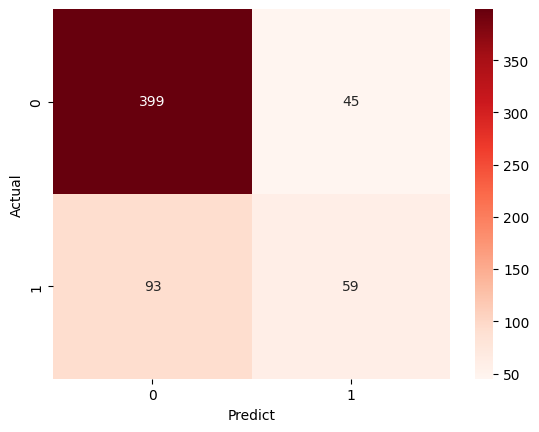

In [11]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, lr_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds')
plt.xlabel('Predict'); plt.ylabel('Actual')
plt.show()

<details><summary>💡 힌트 (막히면 클릭)</summary>

`fmt='d'` 는 정수로 표시

</details>

In [12]:
check.p04_q5()

✅ [P04 문제 5] 혼동행렬 — 정답!
   [[TN FP] [FN TP]] = [[399, 45], [93, 59]]


### ✏️ 문제 6. classification_report
클래스별 지표 표를 문자열로 **`report`** 에 저장하고 출력하세요.

In [13]:
from sklearn.metrics import classification_report
report = classification_report(y_test, lr_pred)
print(report)

              precision    recall  f1-score   support

           0       0.81      0.90      0.85       444
           1       0.57      0.39      0.46       152

    accuracy                           0.77       596
   macro avg       0.69      0.64      0.66       596
weighted avg       0.75      0.77      0.75       596



<details><summary>💡 힌트 (막히면 클릭)</summary>

한 번에 precision/recall/f1/support 를 다 보여줘요. 시험에서 빠르게 확인할 때 좋아요.

</details>

In [14]:
check.p04_q6()

✅ [P04 문제 6] classification_report — 정답!


## 3. 여러 분류 모델 — 바꾸는 건 ② 만들기 줄 뿐!
| 모델 | 위치 | 핵심 하이퍼파라미터 | 한 줄 설명 |
|---|---|---|---|
| KNN | `sklearn.neighbors` | `n_neighbors` | 가장 가까운 이웃 k명의 다수결 |
| 결정트리 | `sklearn.tree` | `max_depth`, `min_samples_split` | 스무고개 질문 나무 |
| 랜덤포레스트 | `sklearn.ensemble` | `n_estimators`, `max_depth` | 나무 여러 그루의 다수결 (배깅) |
| XGBoost | `xgboost` | `n_estimators`, `max_depth`, `learning_rate` | 앞 나무의 실수를 다음 나무가 보완 (부스팅) |
| LightGBM | `lightgbm` | `n_estimators`, `num_leaves` | 더 빠른 부스팅 |

> 📝 `random_state` 를 문제에서 주면 **반드시 그대로** 넣으세요. 채점이 그 결과 기준이에요.

### ✏️ 문제 7. KNN
**`n_neighbors=5`** 로 **`knn`** 을 만들고 학습 → 예측 결과를 **`knn_pred`** 에 저장하세요.

In [15]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

<details><summary>💡 힌트 (막히면 클릭)</summary>

KNN 은 거리를 재기 때문에 스케일링이 특히 중요해요.

</details>

In [16]:
check.p04_q7()

✅ [P04 문제 7] KNN — 정답!


### ✏️ 문제 8. DecisionTree
**`max_depth=5, random_state=42`** 로 **`dt`** → **`dt_pred`**

In [17]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

<details><summary>💡 힌트 (막히면 클릭)</summary>

max_depth 가 너무 크면 학습 데이터만 외워서(과적합) 시험(test)을 못 봐요.

</details>

In [18]:
check.p04_q8()

✅ [P04 문제 8] DecisionTree — 정답!


### ✏️ 문제 9. RandomForest
**`n_estimators=100, max_depth=8, random_state=42`** 로 **`rf`** → **`rf_pred`**

In [19]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

<details><summary>💡 힌트 (막히면 클릭)</summary>

n_estimators = 나무 개수

</details>

In [20]:
check.p04_q9()

✅ [P04 문제 9] RandomForest — 정답!


### ✏️ 문제 10. XGBoost
**`n_estimators=100, max_depth=4, learning_rate=0.1, random_state=42`** 로 **`xgb`** → **`xgb_pred`**

In [21]:
from xgboost import XGBClassifier
xgb = XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.1, random_state=42)
xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)

<details><summary>💡 힌트 (막히면 클릭)</summary>

xgboost 는 sklearn 이 아니라 `from xgboost import XGBClassifier`

</details>

In [22]:
check.p04_q10()

✅ [P04 문제 10] XGBoost — 정답!


### ✏️ 문제 11. LightGBM
**`n_estimators=100, random_state=42, verbose=-1`** 로 **`lgbm`** → **`lgbm_pred`**

In [23]:
from lightgbm import LGBMClassifier
lgbm = LGBMClassifier(n_estimators=100, random_state=42, verbose=-1)
lgbm.fit(X_train, y_train)
lgbm_pred = lgbm.predict(X_test)

<details><summary>💡 힌트 (막히면 클릭)</summary>

verbose=-1 은 학습 로그를 끄는 옵션

</details>

In [24]:
check.p04_q11()

✅ [P04 문제 11] LightGBM — 정답!


### 모델 성적표 (그냥 실행)

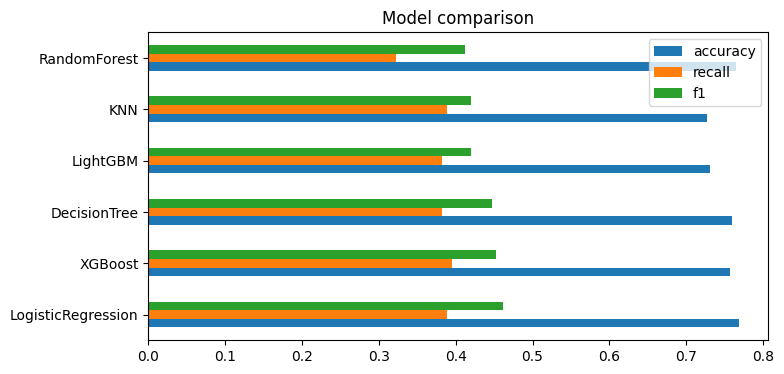

,accuracy,recall,f1
LogisticRegression,0.768,0.388,0.461
KNN,0.727,0.388,0.420
DecisionTree,0.760,0.382,0.448
RandomForest,0.765,0.322,0.412
XGBoost,0.757,0.395,0.453
LightGBM,0.732,0.382,0.420


In [25]:
preds = {'LogisticRegression': lr_pred, 'KNN': knn_pred, 'DecisionTree': dt_pred,
         'RandomForest': rf_pred, 'XGBoost': xgb_pred, 'LightGBM': lgbm_pred}
results = pd.DataFrame({name: {'accuracy': accuracy_score(y_test, p),
                               'recall': recall_score(y_test, p),
                               'f1': f1_score(y_test, p)} for name, p in preds.items()}).T
results.sort_values('f1', ascending=False).plot(kind='barh', figsize=(8, 4), title='Model comparison')
plt.show()
results.round(3)

### ✏️ 문제 12. 최고 모델 고르기
`results` 에서 **F1 이 가장 높은 모델 이름**을 **`best_model_name`** 에 저장하세요.

In [26]:
best_model_name = results['f1'].idxmax()
best_model_name

'LogisticRegression'

<details><summary>💡 힌트 (막히면 클릭)</summary>

`idxmax()` = 가장 큰 값이 있는 **인덱스(이름)**, `max()` = 가장 큰 **값**

</details>

In [27]:
check.p04_q12()

✅ [P04 문제 12] 최고 모델 고르기 — 정답!
   F1 1등: LogisticRegression


### ✏️ 문제 13. 특성 중요도
랜덤포레스트가 **어떤 컬럼을 중요하게 봤는지** `rf.feature_importances_` 로 확인하세요.
`feature_names` 를 인덱스로 하는 Series 를 만들어 **큰 순서로 정렬**해서 **`importances`** 에 저장합니다.

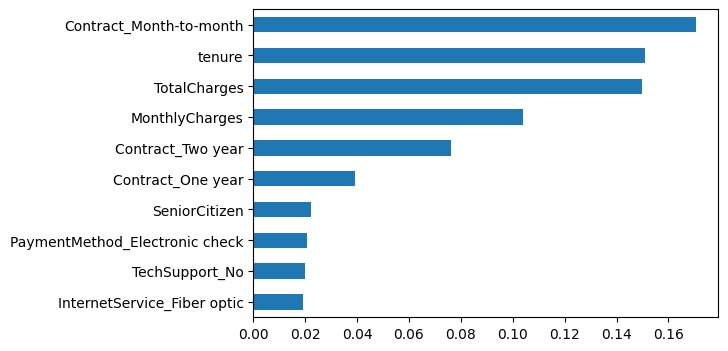

In [28]:
importances = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
importances.head(10).plot(kind='barh', figsize=(6, 4)); plt.gca().invert_yaxis(); plt.show()

<details><summary>💡 힌트 (막히면 클릭)</summary>

EDA 에서 본 것처럼 tenure, Contract, TotalCharges 쪽이 상위권이에요.

</details>

In [29]:
check.p04_q13()

✅ [P04 문제 13] 특성 중요도 — 정답!
   Top3: ['Contract_Month-to-month', 'tenure', 'TotalCharges']


## 4. 재현율이 낮을 때 — 두 가지 처방
### 처방 ① 임계값(threshold) 낮추기
`predict()` 는 확률 0.5 이상이면 1. 기준을 0.3 으로 낮추면 "떠날 것 같은 사람"을 더 많이 잡아요. (대신 헛경보↑)

### ✏️ 문제 14. predict_proba + 임계값
rf 의 '1일 확률'을 구하고, **0.3 이상이면 1** 인 예측을 **`pred_03`** 에 저장하세요.

In [30]:
proba = rf.predict_proba(X_test)[:, 1]       # 열 0 = 0일 확률, 열 1 = 1일 확률
pred_03 = (proba >= 0.3).astype(int)
print('재현율 0.5 기준:', round(recall_score(y_test, rf_pred), 3), '→ 0.3 기준:', round(recall_score(y_test, pred_03), 3))

재현율 0.5 기준: 0.322 → 0.3 기준: 0.789


<details><summary>💡 힌트 (막히면 클릭)</summary>

`[:, 1]` 은 '모든 행의 1번 열'

</details>

In [31]:
check.p04_q14()

✅ [P04 문제 14] 임계값 낮추기 (재현율↑) — 정답!
   재현율 0.322 → 0.789


### 처방 ② SMOTE — 적은 쪽(이탈) 데이터를 비슷하게 만들어 늘리기
> ⚠️ 오버샘플링은 **학습 데이터에만**! test 는 실제 상황 그대로 둬야 해요.

### ✏️ 문제 15. SMOTE
**`SMOTE(random_state=42)`** 로 학습 데이터를 늘려 **`X_over, y_over`** 에 저장하세요.

In [32]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_over, y_over = smote.fit_resample(X_train, y_train)
print(pd.Series(y_train).value_counts().to_dict(), '→', pd.Series(y_over).value_counts().to_dict())

rf_over = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42).fit(X_over, y_over)
print('재현율:', round(recall_score(y_test, rf_pred), 3), '→ SMOTE 후', round(recall_score(y_test, rf_over.predict(X_test)), 3))

{0: 1774, 1: 607} → {0: 1774, 1: 1774}


재현율: 0.322 → SMOTE 후 0.724


<details><summary>💡 힌트 (막히면 클릭)</summary>

`fit_resample(X, y)`

</details>

In [33]:
check.p04_q15()

✅ [P04 문제 15] SMOTE 오버샘플링 — 정답!
   2381 → 3548행


## 5. 회귀 — 숫자를 맞히는 문제 (아파트 가격, 단위: 만원)
| 지표 | 뜻 | 좋은 방향 |
|---|---|---|
| **MAE** | 평균적으로 몇 만원 틀렸나 (절댓값 평균) | 작을수록 |
| **MSE** | 오차 제곱의 평균 (큰 실수에 큰 벌점) | 작을수록 |
| **RMSE** | MSE 의 제곱근 → 원래 단위로 돌아옴 | 작을수록 |
| **R²** | 1 에 가까울수록 잘 설명 (0 = 평균 찍기 수준) | 클수록 |

In [34]:
# --- 아파트 가격 데이터 전처리 (그냥 실행) ---
house = pd.read_csv(DATA_DIR + 'house_price.csv')
house = house[house['area_m2'] < 300]                               # 면적 입력 오류 제거
house['built_year'] = house['built_year'].fillna(house['built_year'].median())
house['station_dist_m'] = house['station_dist_m'].fillna(house['station_dist_m'].median())
house_preset = pd.get_dummies(house, columns=['region', 'parking'], dtype=int)
Xh = house_preset.drop('price', axis=1)
yh = house_preset['price']
Xh_train, Xh_test, yh_train, yh_test = train_test_split(Xh, yh, test_size=0.2, random_state=42)
Xh_train.shape, Xh_test.shape

((1595, 14), (399, 14))

### ✏️ 문제 16. LinearRegression
선형회귀 **`lin`** 을 학습하고 **`lin_pred`** 를 구하세요.

In [35]:
from sklearn.linear_model import LinearRegression
lin = LinearRegression()
lin.fit(Xh_train, yh_train)
lin_pred = lin.predict(Xh_test)

<details><summary>💡 힌트 (막히면 클릭)</summary>

회귀는 stratify 를 쓰지 않아요 (정답이 연속값이라)

</details>

In [36]:
check.p04_q16()

✅ [P04 문제 16] LinearRegression — 정답!


### ✏️ 문제 17. DecisionTreeRegressor (공식 샘플 11번 그대로)
**`max_depth=5, min_samples_split=3, random_state=120`** 으로 **`dtr`** 을 만들고 학습 → **`dtr_pred`**

In [37]:
from sklearn.tree import DecisionTreeRegressor
dtr = DecisionTreeRegressor(max_depth=5, min_samples_split=3, random_state=120)
dtr.fit(Xh_train, yh_train)
dtr_pred = dtr.predict(Xh_test)

<details><summary>💡 힌트 (막히면 클릭)</summary>

분류는 Classifier, 회귀는 Regressor

</details>

In [38]:
check.p04_q17()

✅ [P04 문제 17] DecisionTreeRegressor (샘플문항 파라미터) — 정답!


### ✏️ 문제 18. RandomForestRegressor
**`n_estimators=100, random_state=42`** 로 **`rfr`** → **`rfr_pred`**

In [39]:
from sklearn.ensemble import RandomForestRegressor
rfr = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rfr.fit(Xh_train, yh_train)
rfr_pred = rfr.predict(Xh_test)

<details><summary>💡 힌트 (막히면 클릭)</summary>

n_jobs=-1 은 CPU 를 모두 써서 빠르게

</details>

In [40]:
check.p04_q18()

✅ [P04 문제 18] RandomForestRegressor — 정답!


### ✏️ 문제 19. 회귀 지표
rfr 의 **`rfr_mae`**, **`rfr_mse`**, **`rfr_rmse`**, **`rfr_r2`** 를 구하세요.

In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
rfr_mae = mean_absolute_error(yh_test, rfr_pred)
rfr_mse = mean_squared_error(yh_test, rfr_pred)
rfr_rmse = np.sqrt(rfr_mse)
rfr_r2 = r2_score(yh_test, rfr_pred)
print(f'MAE {rfr_mae:,.0f} | MSE {rfr_mse:,.0f} | RMSE {rfr_rmse:,.0f} | R2 {rfr_r2:.3f}')

MAE 949 | MSE 1,655,142 | RMSE 1,287 | R2 0.945


<details><summary>💡 힌트 (막히면 클릭)</summary>

공식 샘플 12번: `dt_mae = mean_absolute_error(y_valid, y_pred)`

</details>

In [42]:
check.p04_q19()

✅ [P04 문제 19] 회귀 지표 — 정답!
   MAE 949만원, R² 0.945


In [43]:
reg_results = pd.DataFrame({name: {'MAE': mean_absolute_error(yh_test, p), 'R2': r2_score(yh_test, p)}
                            for name, p in {'LinearRegression': lin_pred, 'DecisionTree': dtr_pred,
                                            'RandomForest': rfr_pred}.items()}).T
reg_results.round(3)

,MAE,R2
LinearRegression,1220.362,0.917
DecisionTree,1786.048,0.819
RandomForest,949.257,0.945


### ✏️ 문제 20. 최고 회귀 모델
`reg_results` 에서 **MAE 가 가장 작은** 모델 이름을 **`best_reg_name`** 에 저장하세요.

In [44]:
best_reg_name = reg_results['MAE'].idxmin()
best_reg_name

'RandomForest'

<details><summary>💡 힌트 (막히면 클릭)</summary>

오차는 작을수록 좋으니 idxmin

</details>

In [45]:
check.p04_q20()

✅ [P04 문제 20] 최고 회귀 모델 — 정답!
   MAE 1등: RandomForest


## 🏁 마무리

In [46]:
check.progress()

P04: 20/20 정답 ■■■■■■■■■■■■■■■■■■■■


| 할 일 | 분류 | 회귀 |
|---|---|---|
| 모델 | `RandomForestClassifier` 등 | `RandomForestRegressor` 등 |
| split | `stratify=y` 권장 | stratify 안 씀 |
| 지표 | `accuracy_score`, `recall_score`, `f1_score`, `confusion_matrix` | `mean_absolute_error`, `mean_squared_error`, `r2_score` |
| 확률 | `predict_proba(X)[:, 1]` | — |

다음: **`05_딥러닝_실습.ipynb`**